# Notebook 08 — XAI: Integrated Gradients

**Method:** Integrated Gradients — path integral attribution with completeness guarantee  
**Applied to:** LSTM, 1D-CNN, and Transformer  
**Dataset:** NASA CMAPSS — FD001

### What makes IG different from GradientSHAP
IG satisfies the **completeness axiom**: the sum of all 420 attributions
equals exactly `f(x) - f(baseline)`. We verify this after every prediction
using the convergence delta. A delta close to zero is a mathematical proof
that the explanation is complete.


## 0 · Imports

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils.config import DATA_PROC, OUT_MODELS, OUT_FIGURES
from src.models.lstm        import LSTMModel
from src.models.cnn1d       import CNN1DModel
from src.models.transformer import TransformerModel
from src.explainability.integrated_gradients import IGExplainer
from src.explainability.gradientshap         import GradientSHAPExplainer

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'figure.facecolor': 'white'})

SUBSET  = 'FD001'
DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SENSORS = ['s_2','s_3','s_4','s_7','s_8','s_9','s_11',
           's_12','s_13','s_14','s_15','s_17','s_20','s_21']
print(f'Device: {DEVICE}')

Device: cpu


## 1 · Load models and test data

In [3]:
proc   = DATA_PROC / SUBSET
X_test = np.load(proc / 'X_test.npy')
y_test = np.load(proc / 'y_test.npy')

def load_model(cls, name, subset=SUBSET):
    m = cls()
    ckpt = OUT_MODELS / f'{name}_{subset}_best.pt'
    m.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=True))
    m.eval()
    return m.to(DEVICE)

lstm_model  = load_model(LSTMModel,        'lstm')
cnn_model   = load_model(CNN1DModel,       'cnn1d')
trans_model = load_model(TransformerModel, 'transformer')

# Select 3 representative engines
target_ruls   = [110, 60, 15]
engine_ids    = [int(np.argmin(np.abs(y_test - t))) for t in target_ruls]
actual_ruls   = [y_test[i] for i in engine_ids]
engine_labels = ['Healthy', 'Mid-life', 'Near-failure']

print('Models loaded ✓')
for label, eid, rul in zip(engine_labels, engine_ids, actual_ruls):
    print(f'  {label:<15} idx={eid}  RUL={rul:.0f}')

Models loaded ✓
  Healthy         idx=8  RUL=111
  Mid-life        idx=42  RUL=59
  Near-failure    idx=55  RUL=15


## 2 · IG attributions — LSTM

Each call takes ~10–20 seconds on CPU (50 gradient evaluations per window).

Healthy: actual=111  pred=120.0  convergence_delta=0.0000
Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\ig_lstm_FD001_healthy.png


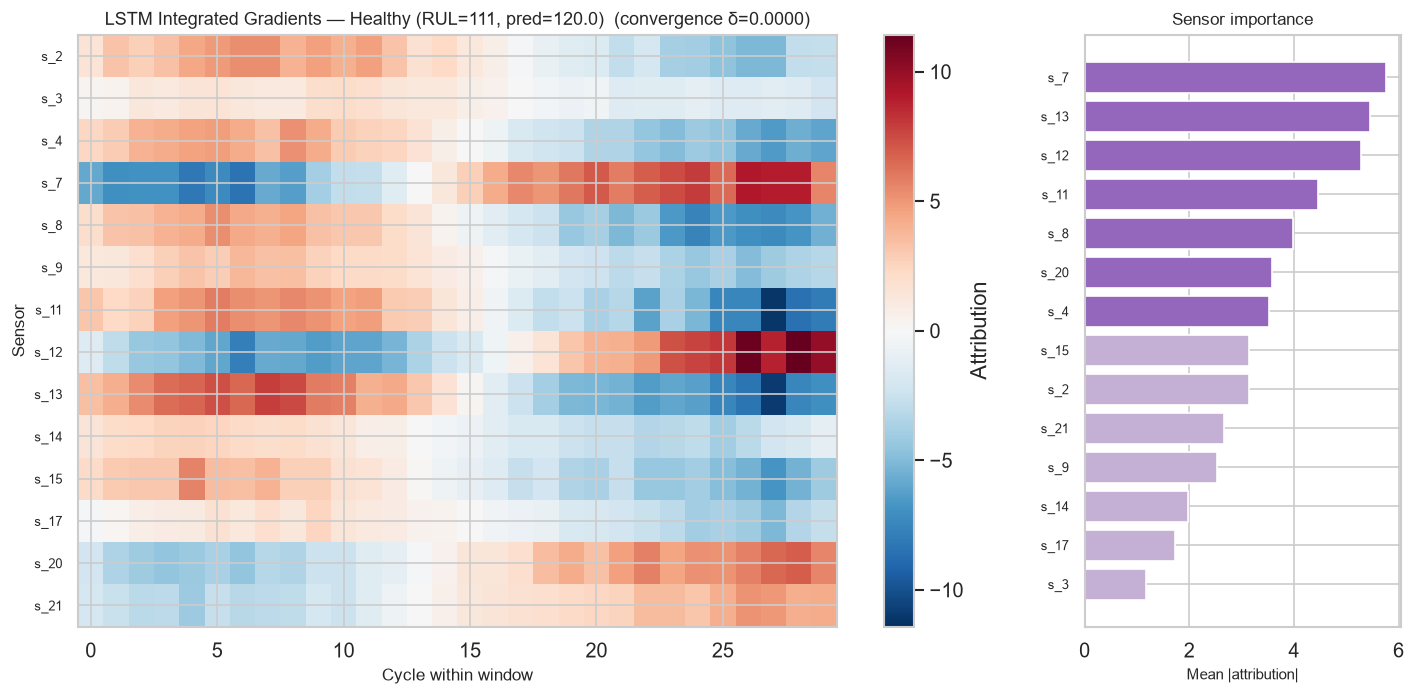

Mid-life: actual=59  pred=60.4  convergence_delta=0.0000
Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\ig_lstm_FD001_mid_life.png


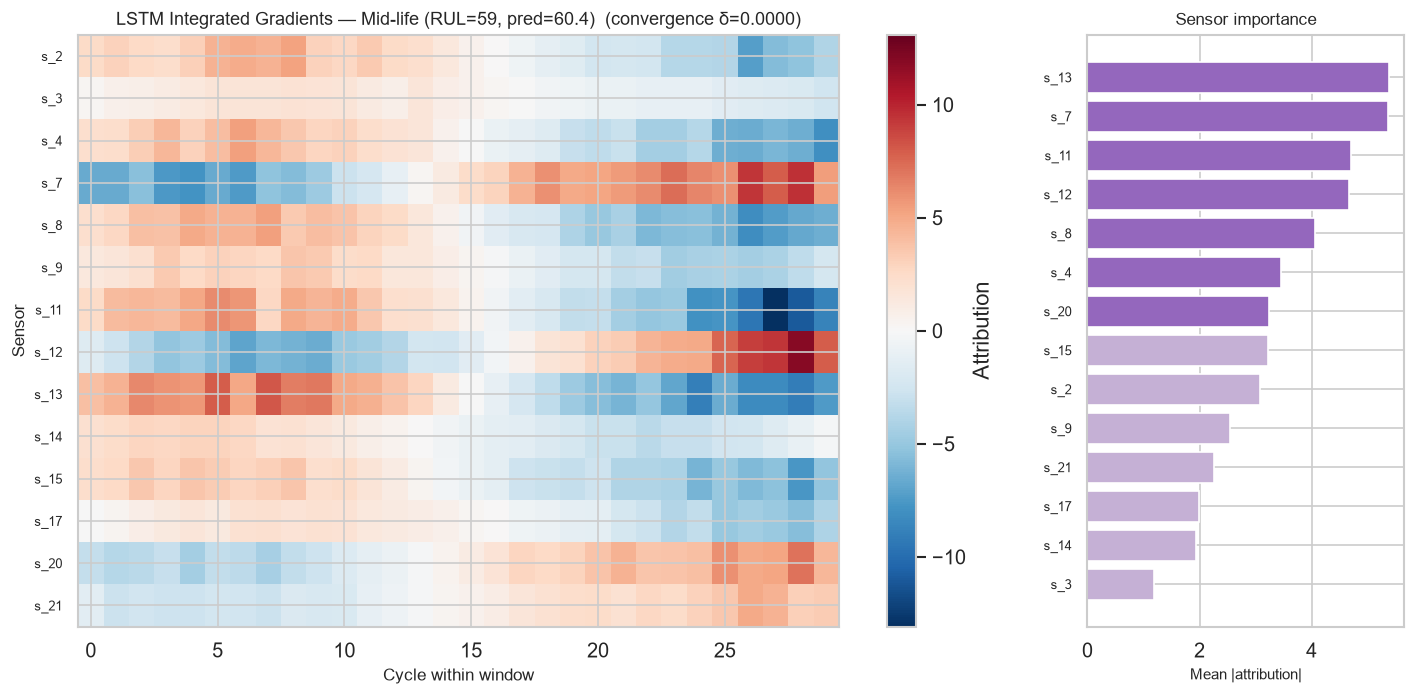

Near-failure: actual=15  pred=17.7  convergence_delta=0.0000
Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\ig_lstm_FD001_near_failure.png


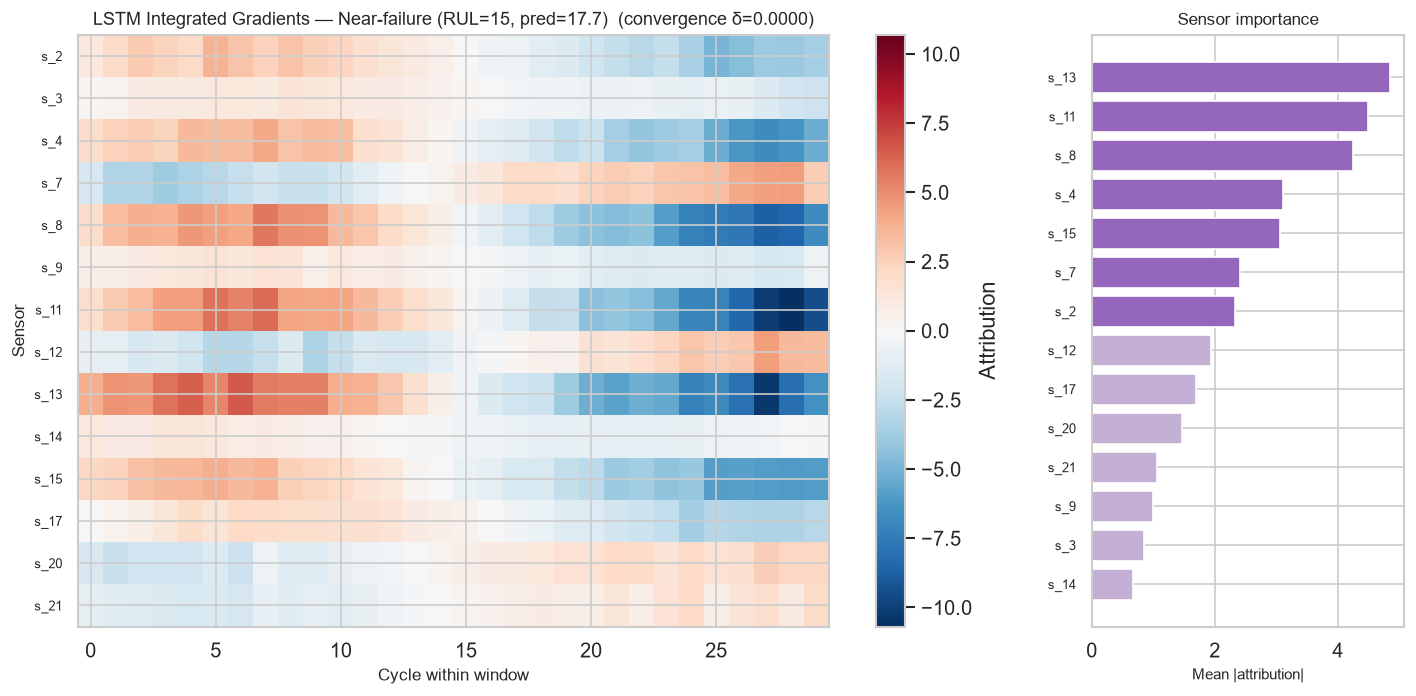

In [4]:
lstm_ig = IGExplainer(lstm_model, DEVICE, n_steps=50)

lstm_ig_attrs = {}

for label, eid, rul in zip(engine_labels, engine_ids, actual_ruls):
    window = torch.tensor(X_test[eid:eid+1], dtype=torch.float32)

    with torch.no_grad():
        pred = lstm_model(window.to(DEVICE)).item()

    attr, delta = lstm_ig.attribute(window)
    lstm_ig_attrs[label] = attr

    print(f'{label}: actual={rul:.0f}  pred={pred:.1f}  convergence_delta={delta:.4f}')

    lstm_ig.plot(
        attr, delta=delta,
        sensor_names=SENSORS,
        title=f'LSTM Integrated Gradients — {label} (RUL={rul:.0f}, pred={pred:.1f})',
        save_path=OUT_FIGURES / f'ig_lstm_{SUBSET}_{label.lower().replace("-","_")}.png',
    )

## 3 · IG attributions — 1D-CNN

Healthy: actual=111  pred=103.4  convergence_delta=1.1314
Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\ig_cnn_FD001_healthy.png


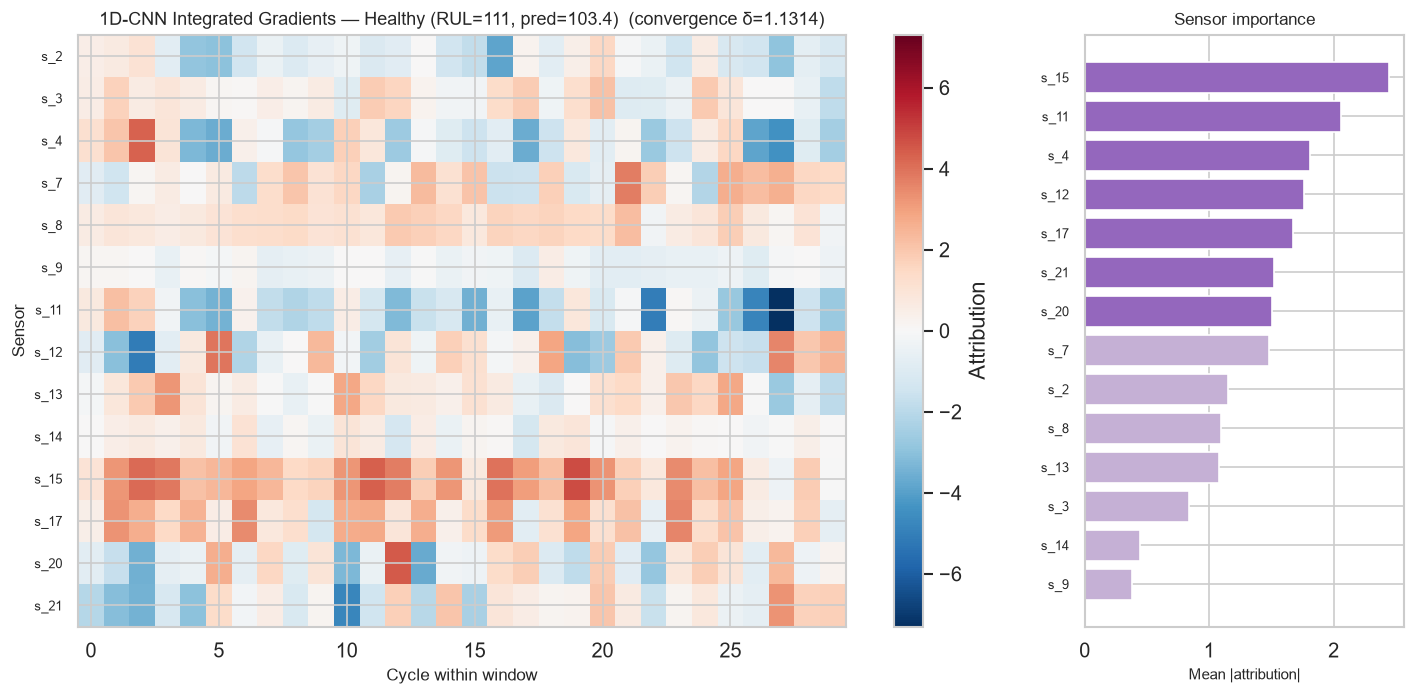

Mid-life: actual=59  pred=82.3  convergence_delta=0.1468
Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\ig_cnn_FD001_mid_life.png


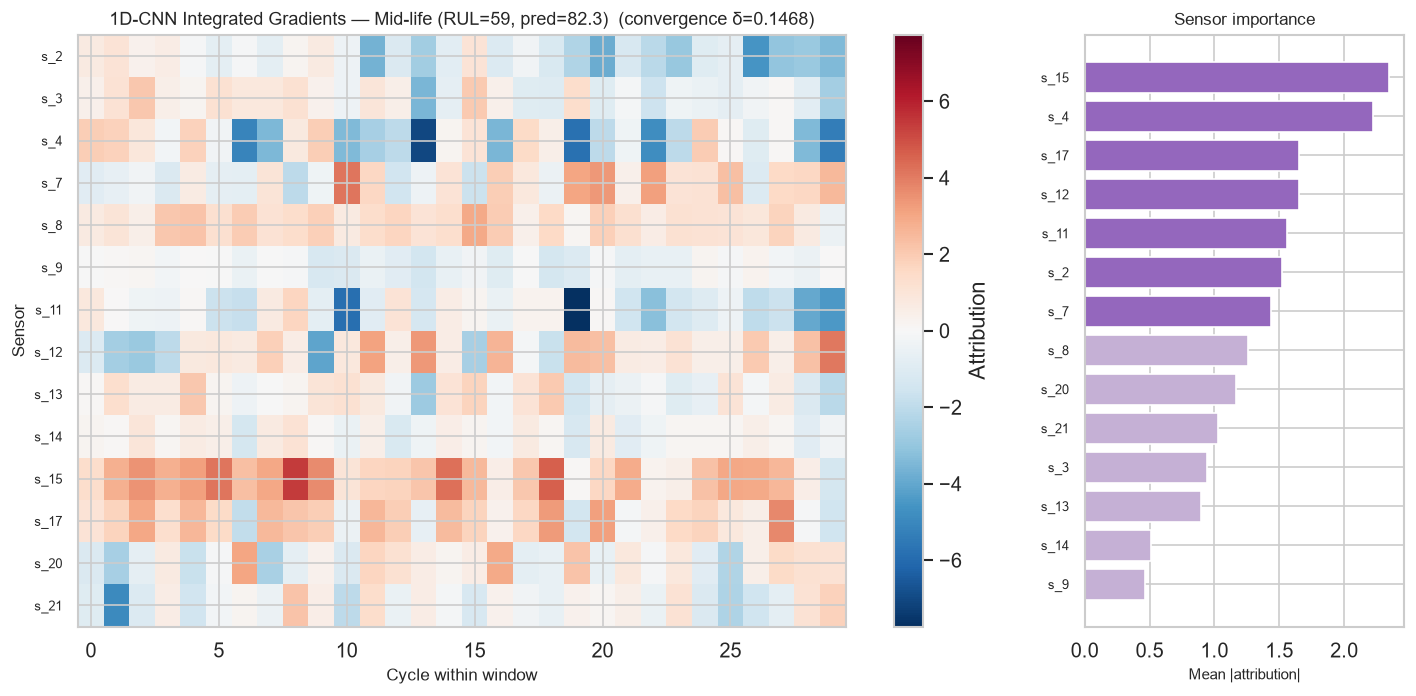

Near-failure: actual=15  pred=6.7  convergence_delta=0.0835
Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\ig_cnn_FD001_near_failure.png


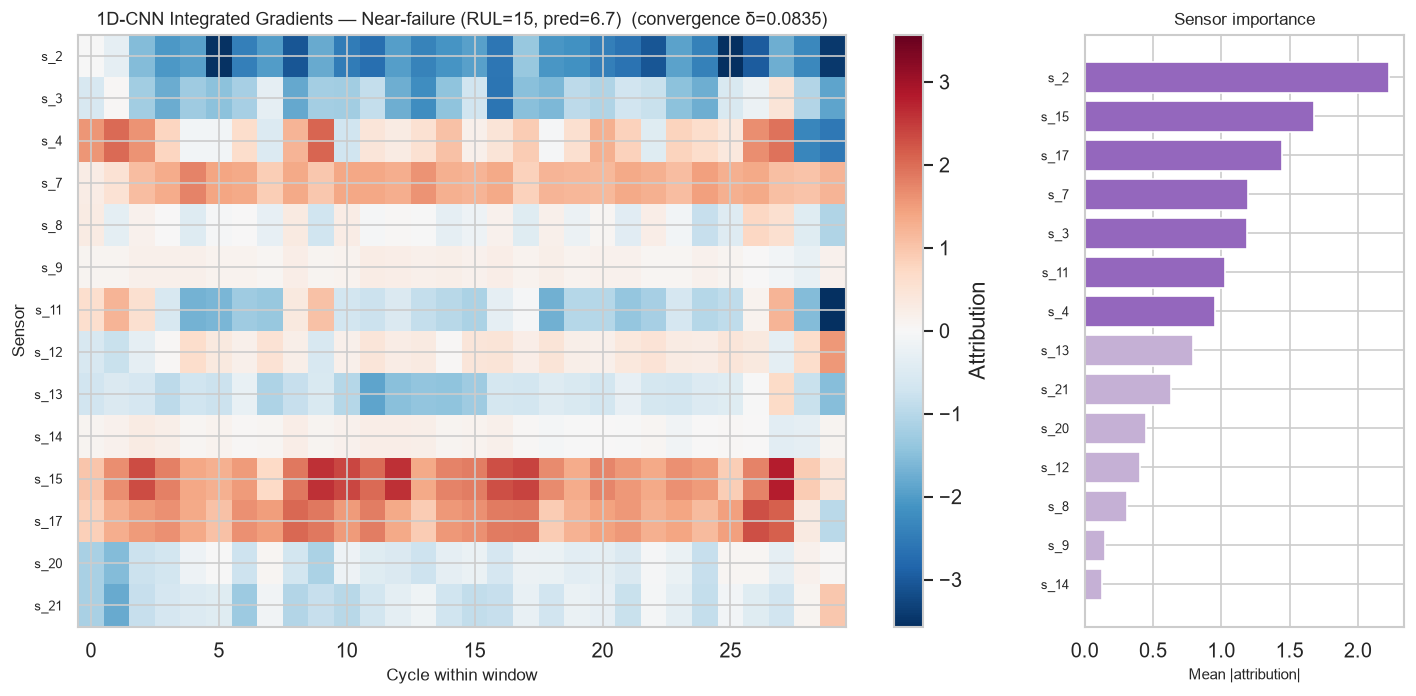

In [5]:
cnn_ig = IGExplainer(cnn_model, DEVICE, n_steps=50)
cnn_ig_attrs = {}

for label, eid, rul in zip(engine_labels, engine_ids, actual_ruls):
    window = torch.tensor(X_test[eid:eid+1], dtype=torch.float32)

    with torch.no_grad():
        pred = cnn_model(window.to(DEVICE)).item()

    attr, delta = cnn_ig.attribute(window)
    cnn_ig_attrs[label] = attr

    print(f'{label}: actual={rul:.0f}  pred={pred:.1f}  convergence_delta={delta:.4f}')

    cnn_ig.plot(
        attr, delta=delta,
        sensor_names=SENSORS,
        title=f'1D-CNN Integrated Gradients — {label} (RUL={rul:.0f}, pred={pred:.1f})',
        save_path=OUT_FIGURES / f'ig_cnn_{SUBSET}_{label.lower().replace("-","_")}.png',
    )

## 4 · IG attributions — Transformer

Healthy: actual=111  pred=118.5  convergence_delta=0.0007
Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\ig_transformer_FD001_healthy.png


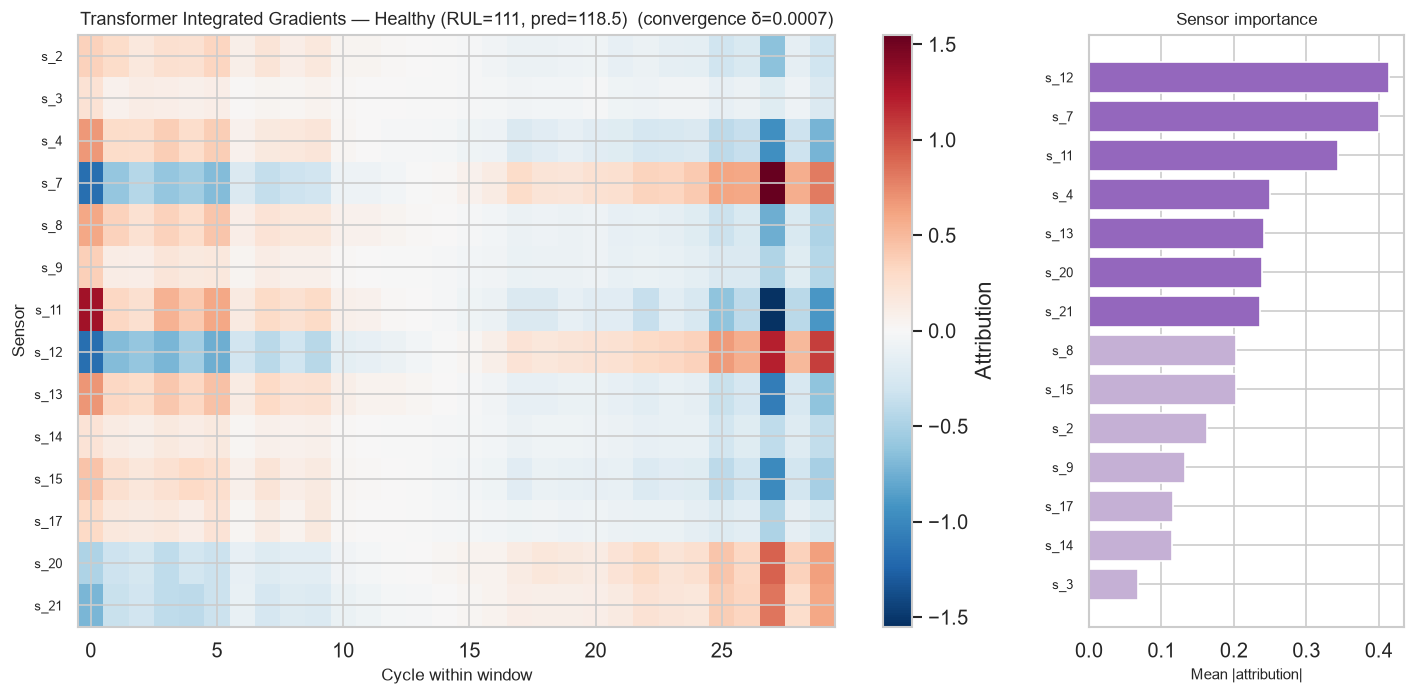

Mid-life: actual=59  pred=58.8  convergence_delta=0.0090
Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\ig_transformer_FD001_mid_life.png


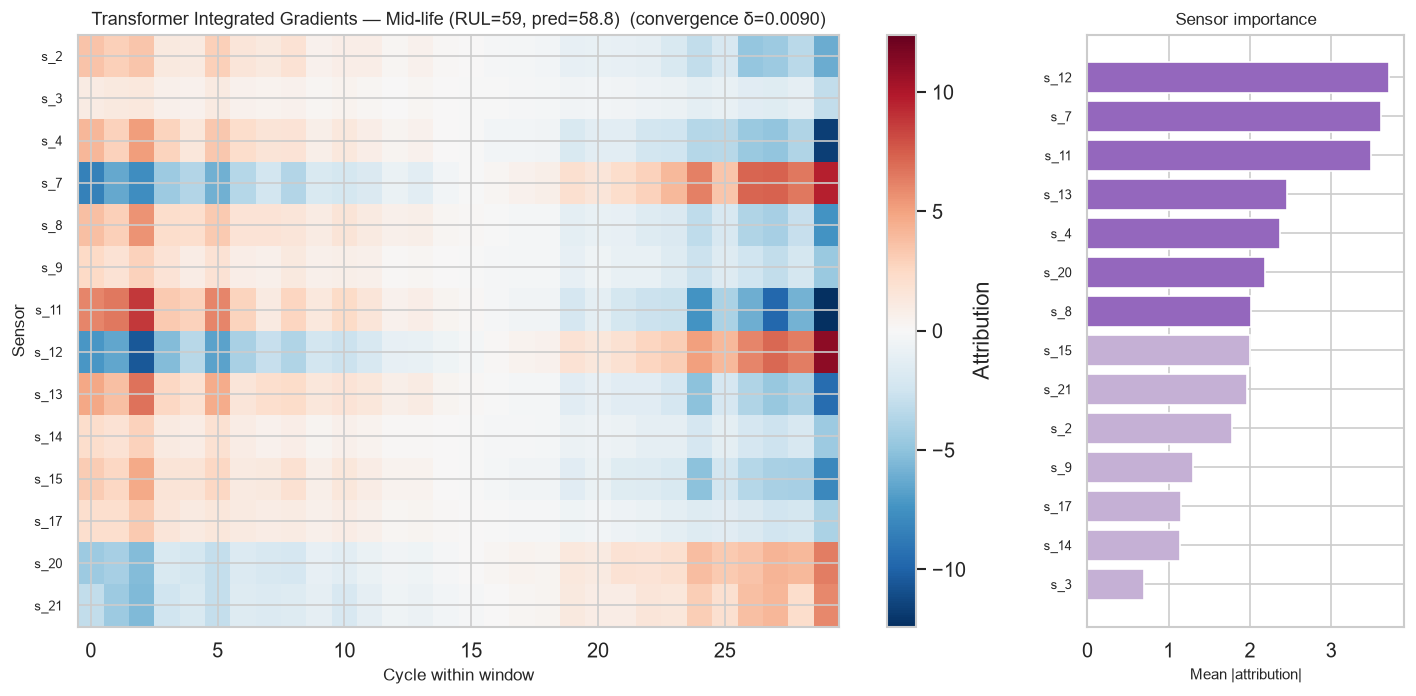

Near-failure: actual=15  pred=18.0  convergence_delta=0.1577
Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\ig_transformer_FD001_near_failure.png


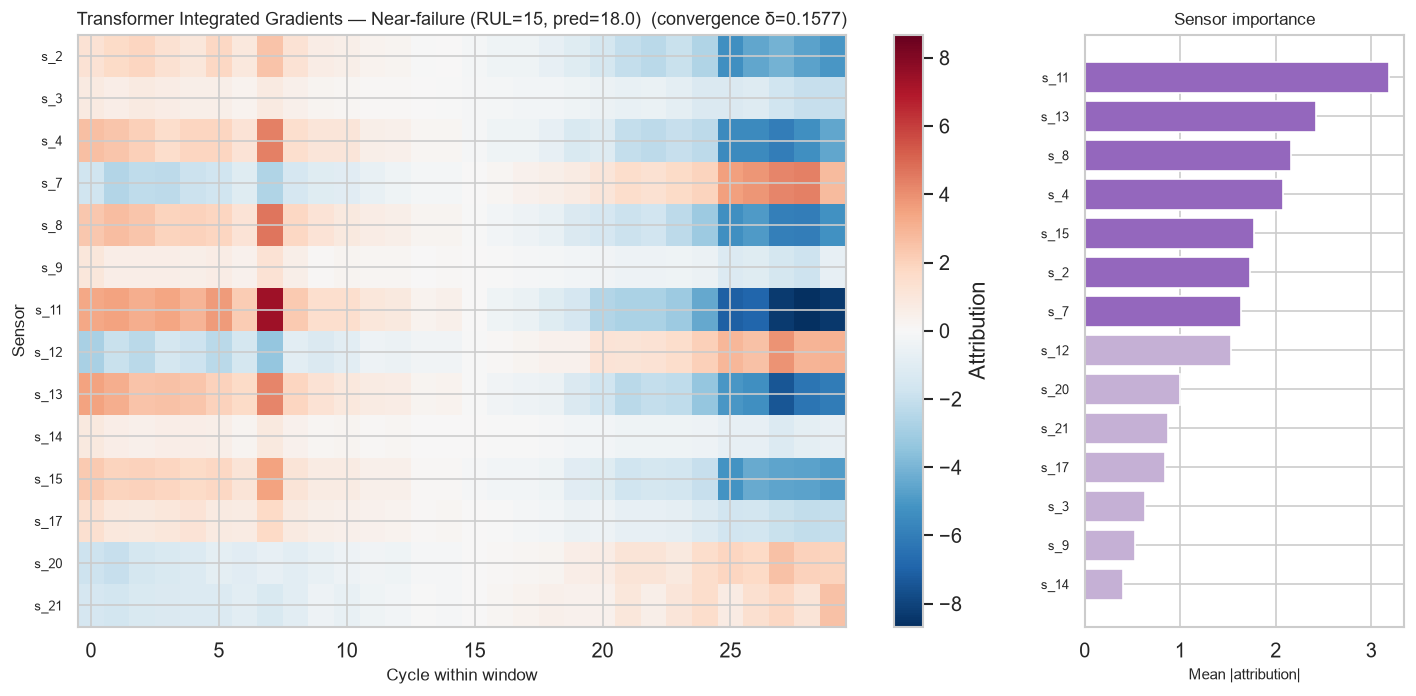

In [6]:
trans_ig = IGExplainer(trans_model, DEVICE, n_steps=50)
trans_ig_attrs = {}

for label, eid, rul in zip(engine_labels, engine_ids, actual_ruls):
    window = torch.tensor(X_test[eid:eid+1], dtype=torch.float32)

    with torch.no_grad():
        pred = trans_model(window.to(DEVICE)).item()

    attr, delta = trans_ig.attribute(window)
    trans_ig_attrs[label] = attr

    print(f'{label}: actual={rul:.0f}  pred={pred:.1f}  convergence_delta={delta:.4f}')

    trans_ig.plot(
        attr, delta=delta,
        sensor_names=SENSORS,
        title=f'Transformer Integrated Gradients — {label} (RUL={rul:.0f}, pred={pred:.1f})',
        save_path=OUT_FIGURES / f'ig_transformer_{SUBSET}_{label.lower().replace("-","_")}.png',
    )

## 5 · IG vs GradientSHAP — convergent validity

If both methods agree on which sensors matter, the explanation is robust.
If they disagree, it reveals something about each method's assumptions.

Computing GradientSHAP for comparison...
  LSTM SHAP done
  CNN1D SHAP done
  Transformer SHAP done

── LSTM ──────────────────────────
Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\ig_vs_shap_lstm_FD001.png


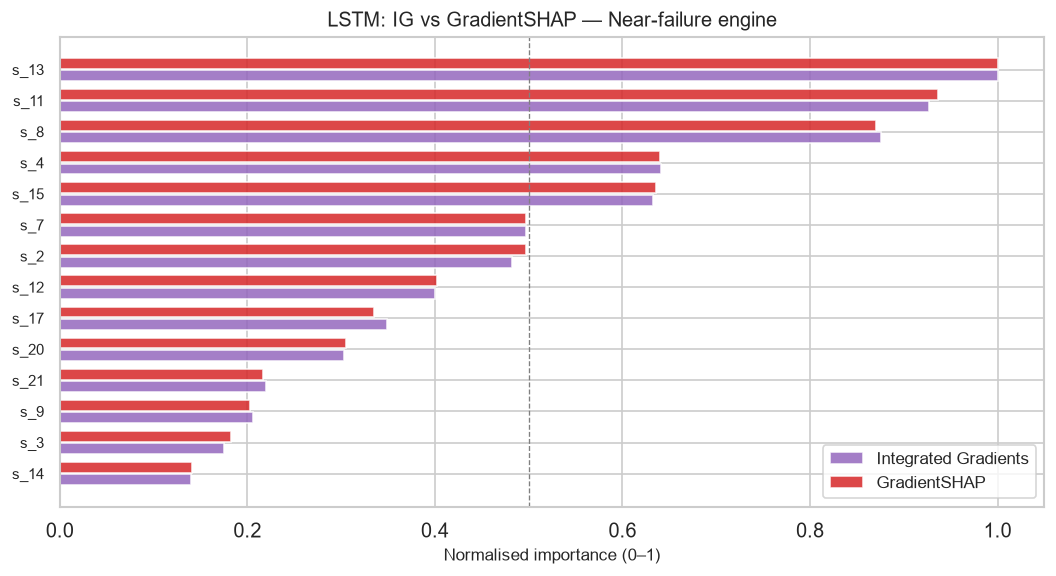


Spearman rank correlation between IG and SHAP importances:
  r = 0.996  (p = 0.0000)
  Strong agreement between methods

── CNN1D ──────────────────────────
Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\ig_vs_shap_cnn1d_FD001.png


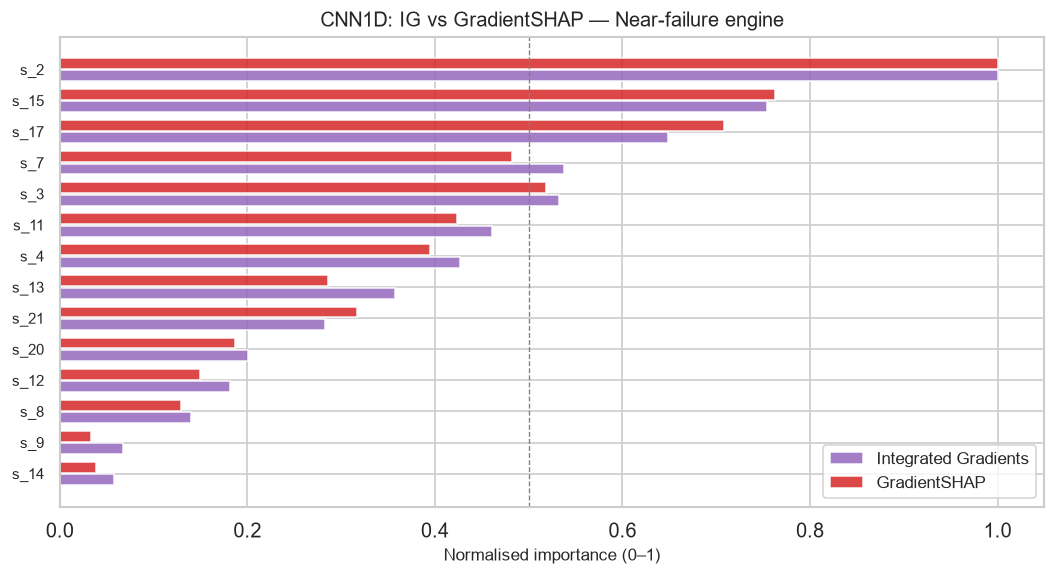


Spearman rank correlation between IG and SHAP importances:
  r = 0.987  (p = 0.0000)
  Strong agreement between methods

── Transformer ──────────────────────────
Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\ig_vs_shap_transformer_FD001.png


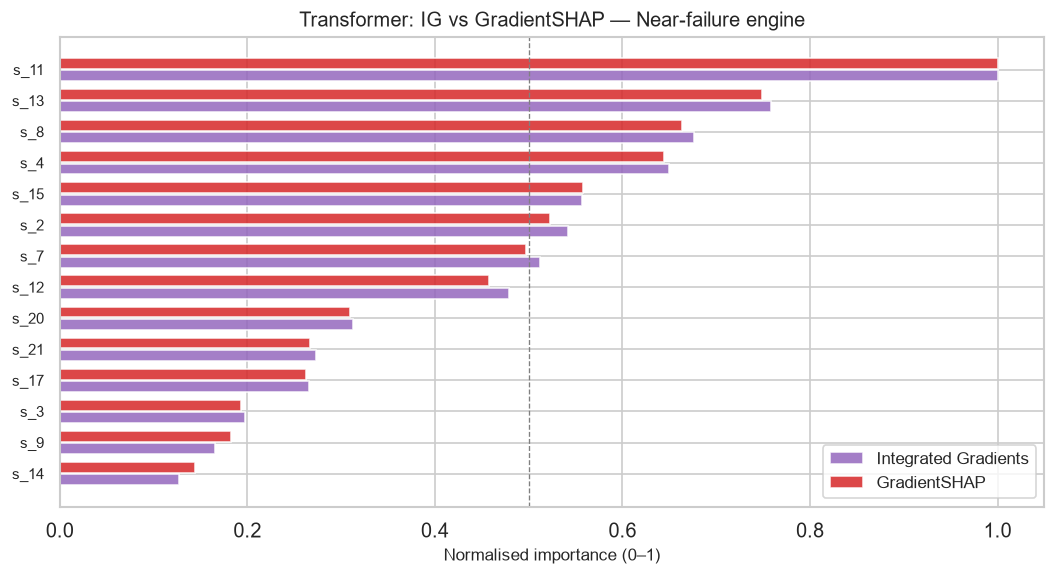


Spearman rank correlation between IG and SHAP importances:
  r = 1.000  (p = 0.0000)
  Strong agreement between methods


In [7]:
# Compute SHAP attributions for the near-failure engine
eid_fail = engine_ids[2]
window   = torch.tensor(X_test[eid_fail:eid_fail+1], dtype=torch.float32)

# SHAP attributions (re-compute for all 3 models)
print('Computing GradientSHAP for comparison...')
shap_attrs = {}
for model, name in [(lstm_model,'LSTM'),(cnn_model,'CNN1D'),(trans_model,'Transformer')]:
    exp = GradientSHAPExplainer(model, DEVICE, n_samples=50)
    shap_attrs[name] = exp.attribute(window)
    print(f'  {name} SHAP done')

# IG attributions for near-failure engine
ig_attrs = {
    'LSTM'        : lstm_ig_attrs['Near-failure'],
    'CNN1D'         : cnn_ig_attrs['Near-failure'],
    'Transformer' : trans_ig_attrs['Near-failure'],
}

# Compare per model
for model_name in ['LSTM', 'CNN1D', 'Transformer']:
    print(f'\n── {model_name} ──────────────────────────')
    ig_exp = IGExplainer(
        {'LSTM': lstm_model, 'CNN1D': cnn_model, 'Transformer': trans_model}[model_name],
        DEVICE
    )
    ig_exp.compare_with_shap(
        ig_attr   = ig_attrs[model_name],
        shap_attr = shap_attrs[model_name],
        sensor_names = SENSORS,
        title = f'{model_name}: IG vs GradientSHAP — Near-failure engine',
        save_path = OUT_FIGURES / f'ig_vs_shap_{model_name.lower()}_{SUBSET}.png',
    )

## 6 · Completeness analysis — all 100 test engines (Transformer)

Running IG on all 100 test engines (Transformer)
  20/100  avg delta so far: 0.0223
  40/100  avg delta so far: 0.0270
  60/100  avg delta so far: 0.0322
  80/100  avg delta so far: 0.0314
  100/100  avg delta so far: 0.0341

Completeness summary:
  Mean delta  : 0.0341
  Max delta   : 0.3083
  % < 0.01    : 52.0%
  % < 0.05    : 80.0%


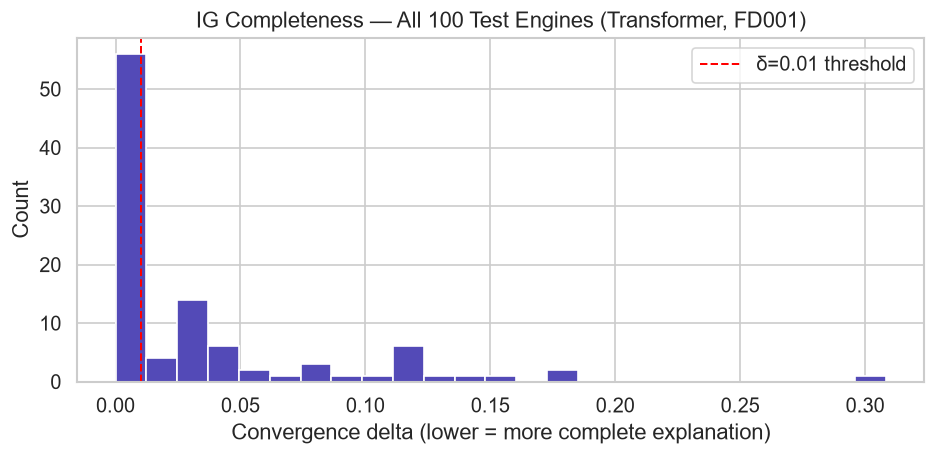

In [8]:
# Run IG on all 100 test engines for the Transformer
# and collect convergence deltas to verify completeness holds globally
print('Running IG on all 100 test engines (Transformer)')

all_deltas = []
all_attrs  = []

for i in range(len(X_test)):
    window = torch.tensor(X_test[i:i+1], dtype=torch.float32)
    attr, delta = trans_ig.attribute(window)
    all_deltas.append(delta)
    all_attrs.append(attr)
    if (i+1) % 20 == 0:
        print(f'  {i+1}/100  avg delta so far: {np.mean(all_deltas):.4f}')

all_deltas = np.array(all_deltas)
all_attrs  = np.stack(all_attrs, axis=0)   # (100, 30, 14)

print(f'\nCompleteness summary:')
print(f'  Mean delta  : {all_deltas.mean():.4f}')
print(f'  Max delta   : {all_deltas.max():.4f}')
print(f'  % < 0.01    : {(all_deltas < 0.01).mean()*100:.1f}%')
print(f'  % < 0.05    : {(all_deltas < 0.05).mean()*100:.1f}%')

# Plot delta distribution
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(all_deltas, bins=25, color='#534AB7', edgecolor='white')
ax.axvline(0.01, color='red', linestyle='--', linewidth=1.2, label='δ=0.01 threshold')
ax.set_xlabel('Convergence delta (lower = more complete explanation)')
ax.set_ylabel('Count')
ax.set_title('IG Completeness — All 100 Test Engines (Transformer, FD001)')
ax.legend()
plt.tight_layout()
plt.savefig(OUT_FIGURES / f'ig_completeness_delta_{SUBSET}.png', bbox_inches='tight')
plt.show()